# Preparación de audio y representaciones del experimento

Esta notebook construye los insumos del detector binario de sirenas de vehículos de emergencia.
Organiza AudioSet-EV v2, sireNNet y A3Siren-Recordings para desarrollo y conserva LSSiren como
reserva predictiva externa. La metodología corresponde a la preparación definida en docs/.

Se obtienen dos representaciones por segmento: **21 características acústicas** para los modelos
tradicionales y **Log-Mel de 64 bandas** para CNN y ResNet18.


## 1. Insumos y configuración

La preparación utiliza los cuatro corpus originales montados en Kaggle. Revisa sus raíces antes de ejecutar. El paquete completo será el insumo común de los cinco modelos; no se requieren CSV de particiones previos.


In [1]:
CFG = {
    "protocol_version": "doppler-prepared-v3",
    "seed": 42,
    "output_root": "/kaggle/working/prepared_data_v3",
    "resume": True,
    "workers": 2,
    "search_roots": ["/kaggle/input"],
    "datasets": {
        "AudioSet-EV v2": {
            "root": "/kaggle/input/datasets/jeancdevx/audioset-ev",
            "slug": "audioset-ev",
            "metadata_override": None,
        },
        "LSSiren": {
            "root": "/kaggle/input/datasets/jeancdevx/lssiren/lssiren",
            "slug": "lssiren",
            "metadata_override": None,
        },
        "sireNNet": {
            "root": "/kaggle/input/datasets/jeancdevx/sirennet/sireNNet",
            "slug": "sirennet",
            "metadata_override": None,
        },
        "A3Siren-Recordings": {
            "root": "/kaggle/input/datasets/jeancdevx/a3s-rec",
            "slug": "a3s-rec",
            "metadata_override": None,
        },
    },
    "extra_folder_labels": {},
    "audioset_label_policy": "documented_folder_with_metadata_audit",
    "a3_require_eight_channels": True,
    "holdout_corpus": "LSSiren",
    "sample_rate": 16000,
    "window_seconds": 3.0,
    "hop_seconds": 1.5,
    "short_clip_policy": "drop_short_clip",
    "long_tail_policy": "drop_incomplete_tail",
    "channel_strategy": "mean_within_wav_preserve_A3_channels_as_separate_grouped_sources",
    "amplitude_normalization": "peak_per_file",
    "peak_target": 0.99,
    "silence_peak": 1e-06,
    "clipping_fraction": 0.01,
    "n_fft": 2048,
    "stft_hop": 512,
    "n_mels": 64,
    "fmin": 20.0,
    "fmax": 8000.0,
    "stft_window": "periodic_hann",
    "stft_center": True,
    "stft_pad_mode": "constant",
    "mel_scale": "slaney",
    "mel_normalization": "area_slaney",
    "power": 2,
    "db_reference": "segment_max",
    "db_amin": 1e-10,
    "top_db": 80.0,
    "mfcc_orders": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
    "rolloff": 0.85,
    "new_augmentation": False,
    "global_feature_scaling": False,
    "disk_reserve_gib": 2.0,
    "make_full_zip": True,
    "metadata_chunk_rows": 100000,
    "validation_fraction": 0.2,
    "heartbeat_seconds": 30,
}

In [2]:
def validate_preparation_config(config):
    """Solo permite convenciones implementadas por el extractor."""
    required = {
        "sample_rate": 16000,
        "window_seconds": 3.0,
        "hop_seconds": 1.5,
        "n_fft": 2048,
        "stft_hop": 512,
        "n_mels": 64,
        "fmin": 20.0,
        "fmax": 8000.0,
        "peak_target": 0.99,
        "amplitude_normalization": "peak_per_file",
    }
    for key, expected in required.items():
        if config[key] != expected:
            raise ValueError(
                f"Convención fuera del protocolo: {key}={config[key]!r}; se requiere {expected!r}."
            )
    if not isinstance(config["workers"], int) or config["workers"] < 1:
        raise ValueError("workers debe ser un entero positivo.")
    if not 0 < config["validation_fraction"] < 1:
        raise ValueError("validation_fraction debe estar entre cero y uno.")

In [3]:
validate_preparation_config(CFG)

### Dependencias

Librosa y SoundFile mantienen las convenciones acústicas del proyecto. Se registran versiones efectivas y no se instalan paquetes automáticamente.


In [4]:
import os
import sys
import re
import json
import time
import hashlib
import math
import shutil
import zipfile
import platform

from pathlib import Path

from datetime import datetime, timezone

from importlib.metadata import version, PackageNotFoundError

from concurrent.futures import ThreadPoolExecutor

from collections import deque

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

from scipy.io import wavfile

import librosa

from threadpoolctl import threadpool_limits

try:
    import soundfile as sf
except ImportError:
    sf = None

try:
    from IPython.display import display
except ImportError:

    def display(x):
        print(x)

### Salida y reanudación

La salida se escribe en `/kaggle/working/prepared_data_v3`. Una reanudación exige la misma configuración y, antes de reutilizar filas, la misma identidad de fuentes y del plan de índices. Usa una salida nueva si cambia esa identidad.


In [5]:
def bounded_map(pool, fn, iterable):
    iterator = iter(iterable)
    pending = deque()
    for _ in range(2 * CFG["workers"]):
        try:
            pending.append(pool.submit(fn, next(iterator)))
        except StopIteration:
            break
    try:
        while pending:
            result = pending.popleft().result()
            yield result
            try:
                pending.append(pool.submit(fn, next(iterator)))
            except StopIteration:
                pass
    finally:
        for future in pending:
            future.cancel()

In [6]:
def digest(value):
    return hashlib.sha256(str(value).encode("utf-8")).hexdigest()

In [7]:
def sha_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(1024 * 1024), b""):
            h.update(b)
    return h.hexdigest()

In [8]:
def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(
        json.dumps(
            value,
            ensure_ascii=False,
            indent=2,
            default=lambda x: x.item() if isinstance(x, np.generic) else str(x),
        )
    )
    tmp.replace(path)

In [9]:
def table(path, rows):
    df = rows if isinstance(rows, pd.DataFrame) else pd.DataFrame(rows)
    p = OUT / path
    p.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(p, index=False)
    return df

In [10]:
def fail(message):
    write_json(
        OUT / "reports/failure.json", {"status": "BLOCKED", "message": str(message)}
    )
    p = OUT.parent / (OUT.name + "_diagnostico.zip")
    with zipfile.ZipFile(p, "w", zipfile.ZIP_DEFLATED) as z:
        for folder in ["config", "reports", "metadata"]:
            for f in (OUT / folder).rglob("*"):
                if f.is_file():
                    z.write(f, str(f.relative_to(OUT)))
    print("Diagnóstico:", p)
    raise ValueError(message)

In [11]:
OUT = Path(CFG["output_root"]).resolve()

if OUT == Path("/kaggle/input") or Path("/kaggle/input") in OUT.parents:
    raise ValueError("Salida dentro de input prohibida.")

config_identity = {
    k: v for k, v in CFG.items() if k not in ["resume", "workers", "make_full_zip"]
}

CONFIG_HASH = digest(json.dumps(config_identity, sort_keys=True))

if OUT.exists() and any(OUT.iterdir()):
    state = OUT / "config/run_identity.json"
    if (
        not CFG["resume"]
        or not state.is_file()
        or json.loads(state.read_text())["config_sha256"] != CONFIG_HASH
    ):
        raise ValueError(
            "La salida ya contiene datos. Usa otra output_root o resume=True con la misma configuración."
        )

for folder in [
    "metadata",
    "splits",
    "features",
    "representations/logmel",
    "reports",
    "figures",
    "config",
    "_staging",
]:
    (OUT / folder).mkdir(parents=True, exist_ok=True)

for old in ["PREPARATION_READY.json", "metadata/metadata_segments.csv"]:
    (OUT / old).unlink(missing_ok=True)

START = time.perf_counter()

COSTS = []

fixed = {
    "short_clip_policy": "drop_short_clip",
    "long_tail_policy": "drop_incomplete_tail",
    "channel_strategy": "mean_within_wav_preserve_A3_channels_as_separate_grouped_sources",
    "stft_window": "periodic_hann",
    "stft_center": True,
    "stft_pad_mode": "constant",
    "mel_scale": "slaney",
    "mel_normalization": "area_slaney",
    "power": 2,
    "db_reference": "segment_max",
    "mfcc_orders": list(range(13)),
    "new_augmentation": False,
    "global_feature_scaling": False,
    "audioset_label_policy": "documented_folder_with_metadata_audit",
}

for key, value in fixed.items():
    if CFG[key] != value:
        fail(f"Convención no implementada para {key}: {CFG[key]}")

if CFG["amplitude_normalization"] not in ["peak_per_file", "none"]:
    fail("Normalización no implementada.")

if CFG["n_mels"] != 64 or CFG["sample_rate"] != 16000 or CFG["window_seconds"] != 3.0:
    fail(
        "Este paquete compatible con los cinco modelos requiere 64 Mel, 16 kHz y ventanas 3 s."
    )

if CFG["n_fft"] % 2 or CFG["n_fft"] < 2 or CFG["stft_hop"] <= 0:
    fail("Parámetros STFT inválidos.")

if not 0 < CFG["rolloff"] < 1 or not 0 < CFG["peak_target"] <= 1:
    fail("Rolloff/pico fuera de rango.")

write_json(OUT / "config/run_identity.json", {"config_sha256": CONFIG_HASH})

write_json(OUT / "config/preparation_config.json", CFG)

packages = {}

for name in [
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "soundfile",
    "threadpoolctl",
    "librosa",
]:
    try:
        packages[name] = version(name)
    except PackageNotFoundError:
        packages[name] = None

ENV = {
    "python": sys.version,
    "platform": platform.platform(),
    "packages": packages,
    "cpu_count": os.cpu_count(),
    "workers": CFG["workers"],
    "audio_reader": "soundfile" if sf else "scipy.wavfile",
    "disk_free_gib": shutil.disk_usage(OUT).free / 1024**3,
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
}

write_json(OUT / "reports/environment.json", ENV)

display(pd.DataFrame([ENV]))

,python,platform,packages,cpu_count,workers,audio_reader,disk_free_gib,timestamp_utc
0,"3.13.15 (main, Aug 6 2026, 11:06:22) [GCC 13....",Linux-6.18.48+-x86_64-with-glibc2.39,"{'numpy': '2.1.3', 'pandas': '2.3.3', 'scipy':...",4,2,soundfile,19.502136,2026-10-12T07:26:06.525714+00:00


In [12]:
def safe_member_path(name):
    """Comprueba las rutas relativas antes de leer o extraer un artefacto."""
    from pathlib import PurePosixPath

    parts = PurePosixPath(name).parts
    if not parts or PurePosixPath(name).is_absolute() or ".." in parts or "\\" in name:
        raise ValueError(f"Ruta relativa inválida: {name}")
    return name

In [13]:
def atomic_zip(destination, entries):
    """Publica un ZIP completo únicamente después de verificar su CRC."""
    destination = Path(destination)
    temporary = destination.with_suffix(destination.suffix + ".partial")
    try:
        with zipfile.ZipFile(
            temporary, "w", zipfile.ZIP_DEFLATED, allowZip64=True
        ) as archive:
            for path, name in entries:
                archive.write(path, safe_member_path(name))
        with zipfile.ZipFile(temporary) as archive:
            invalid = archive.testzip()
            if invalid:
                raise ValueError(f"CRC inválido: {invalid}")
        temporary.replace(destination)
    finally:
        temporary.unlink(missing_ok=True)
    return destination

### Registro persistente

Cada etapa conserva eventos y un diagnóstico ante errores. Los originales se mantienen sin cambios.


In [14]:
import logging
import traceback
import threading

from contextlib import contextmanager

try:
    from tqdm.auto import tqdm
except ImportError:

    class tqdm:
        def __init__(self, iterable=None, total=None, **kwargs):
            self.iterable = iterable

        def __iter__(self):
            return iter(self.iterable)

        def update(self, *args, **kwargs):
            pass

        def set_postfix(self, *args, **kwargs):
            pass

        def close(self):
            pass


try:
    import psutil
except ImportError:
    psutil = None

LOG_DIR = OUT / "logs"

LOG_DIR.mkdir(exist_ok=True)

LOGGER = logging.getLogger("doppler." + str(OUT))

LOGGER.setLevel(logging.INFO)

LOGGER.propagate = False

for h in LOGGER.handlers[:]:
    h.close()
    LOGGER.removeHandler(h)

handler = logging.FileHandler(LOG_DIR / "training.log", encoding="utf-8")

handler.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))

LOGGER.addHandler(handler)

console = logging.StreamHandler(sys.stdout)

console.setFormatter(logging.Formatter("%(asctime)s | %(message)s", datefmt="%H:%M:%S"))

LOGGER.addHandler(console)

In [15]:
def resource_snapshot():
    if psutil:
        return {"rss_mib": psutil.Process().memory_info().rss / 1024**2}
    return {}

In [16]:
def event(kind, console=True, **fields):
    record = {
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "event": kind,
        **resource_snapshot(),
        **fields,
    }
    with open(LOG_DIR / "events.jsonl", "a", encoding="utf-8") as f:
        f.write(json.dumps(record, ensure_ascii=False, default=str) + "\n")
    if console:
        LOGGER.info(
            "%s | %s",
            kind,
            " | ".join(
                f"{k}={v:.5g}" if isinstance(v, float) else f"{k}={v}"
                for k, v in fields.items()
            ),
        )

In [17]:
def diagnostic_bundle():
    import zipfile

    target = OUT.parent / (OUT.name + "_diagnostico.zip")
    with zipfile.ZipFile(target, "w", zipfile.ZIP_DEFLATED) as z:
        for folder in ["config", "reports", "tables", "logs", "metadata"]:
            for p in (OUT / folder).rglob("*"):
                if p.is_file():
                    z.write(p, str(p.relative_to(OUT)))
    return str(target)

In [18]:
@contextmanager
def stage_guard(name):
    tick = time.perf_counter()
    event("stage_start", stage=name)
    try:
        yield
    except Exception as exc:
        error = traceback.format_exc()
        (LOG_DIR / "traceback.txt").write_text(error, encoding="utf-8")
        event(
            "stage_failed",
            stage=name,
            error=str(exc),
            seconds=time.perf_counter() - tick,
        )
        write_json(
            OUT / "reports/run_status.json",
            {"status": "FAILED", "stage": name, "error": str(exc)},
        )
        try:
            print("Diagnóstico guardado:", diagnostic_bundle())
        except Exception as diag_exc:
            print("No se pudo comprimir el diagnóstico:", diag_exc)
        raise
    else:
        event("stage_end", stage=name, seconds=time.perf_counter() - tick)

In [19]:
@contextmanager
def heartbeat(phase, **fields):
    stop = threading.Event()
    tick = time.perf_counter()

    def worker():
        while not stop.wait(CFG.get("heartbeat_seconds", 30)):
            event(
                "fit_running",
                phase=phase,
                elapsed_seconds=time.perf_counter() - tick,
                **fields,
            )

    thread = threading.Thread(target=worker, daemon=True)
    thread.start()
    try:
        yield
    finally:
        stop.set()
        thread.join(timeout=1)

In [20]:
write_json(OUT / "reports/run_status.json", {"status": "RUNNING"})

event("run_start", model=CFG.get("model_name", "preparation"), output=str(OUT))

07:26:07 | run_start | model=preparation | output=/kaggle/working/prepared_data_v3


## 2. Inventario de corpus

Se identifican las raíces y se recorre cada corpus para obtener WAV y CSV. Una raíz vacía o ambigua detiene la ejecución.


In [21]:
def resolve_root(corpus, settings):
    p = Path(settings["root"])
    if p.is_dir():
        return p.resolve()
    matches = []
    for base in CFG["search_roots"]:
        b = Path(base)
        if b.is_dir():
            matches += [q for q in b.rglob(settings["slug"]) if q.is_dir()]
    matches = sorted(set(matches))
    if len(matches) != 1:
        fail(
            f'{corpus}: ruta inexistente o ambigua. Ajusta datasets[{corpus!r}]["root"]. Candidatas: {matches}'
        )
    return matches[0].resolve()

In [22]:
with stage_guard("discovery"):
    ROOTS = {d: resolve_root(d, s) for d, s in CFG["datasets"].items()}

    for root in ROOTS.values():
        if OUT == root or OUT in root.parents or root in OUT.parents:
            fail("La salida no puede solaparse con un corpus original.")

    tick_discovery = time.perf_counter()

    FILES = []

    structure = []

    for dataset, root in ROOTS.items():
        all_files = [
            Path(directory) / filename
            for directory, _, filenames in os.walk(root)
            for filename in filenames
        ]
        wavs = sorted(p for p in all_files if p.suffix.lower() == ".wav")
        if not wavs:
            fail(
                f"{dataset}: no hay WAV extraídos en {root}. Revisa el montaje; no se interpreta como corpus vacío."
            )
        for p in wavs:
            rel = p.relative_to(root).as_posix()
            FILES.append(
                {
                    "dataset": dataset,
                    "relative_path": rel,
                    "original_path": str(p),
                    "file_id": rel,
                }
            )
        structure.append(
            {
                "dataset": dataset,
                "root": str(root),
                "wav_files": len(wavs),
                "csv_files": sum(p.suffix.lower() == ".csv" for p in all_files),
                "examples": " | ".join(str(p.relative_to(root)) for p in wavs[:6]),
            }
        )

    table("reports/input_structure.csv", structure)

    table("metadata/discovered_files.csv", FILES)

    display(pd.DataFrame(structure))

    COSTS.append(
        {"phase": "discovery", "seconds": time.perf_counter() - tick_discovery}
    )

07:26:07 | stage_start | stage=discovery


,dataset,root,wav_files,csv_files,examples
0,AudioSet-EV v2,/kaggle/input/datasets/jeancdevx/audioset-ev,28816,2,Negative_files/balanced_train/--PJHxphWEs.wav ...
1,LSSiren,/kaggle/input/datasets/jeancdevx/lssiren/lssiren,1834,2,Emergency Vehicle Sirens/ambulance1.wav | Emer...
2,sireNNet,/kaggle/input/datasets/jeancdevx/sirennet/sire...,1675,0,ambulance/sound_1.wav | ambulance/sound_10.wav...
3,A3Siren-Recordings,/kaggle/input/datasets/jeancdevx/a3s-rec,104,0,ch1/Noise/n-20210506-1652-ch1.wav | ch1/Noise/...


07:27:08 | stage_end | stage=discovery | seconds=60.972


### Etiquetas y metadata

AudioSet-EV conserva `positive_labels` y utiliza las listas y carpetas documentadas para la clase binaria. Los CSV se leen por chunks y solo se retienen referencias con audio físico. `Road_final.csv` se lee sin encabezado para conservar su primera fila. Las contradicciones necesitan resolución explícita.


In [23]:
def token(s):
    return re.sub(r"[^a-z0-9]+", "", str(s).casefold())

In [24]:
with stage_guard("label_adapters"):
    FOLDER_MAP = {
        "LSSiren": {
            "ambulance": "EMERGENCY",
            "emergencyvehiclesirens": "EMERGENCY",
            "road": "NON_EMERGENCY",
            "roadnoises": "NON_EMERGENCY",
        },
        "sireNNet": {
            "ambulance": "EMERGENCY",
            "firetruck": "EMERGENCY",
            "police": "EMERGENCY",
            "traffic": "NON_EMERGENCY",
        },
        "A3Siren-Recordings": {"siren": "EMERGENCY", "noise": "NON_EMERGENCY"},
        "AudioSet-EV v2": {
            "positivefiles": "EMERGENCY",
            "negativefiles": "NON_EMERGENCY",
        },
    }

    for d, m in CFG["extra_folder_labels"].items():
        FOLDER_MAP[d].update({token(k): v for k, v in m.items()})

07:27:08 | stage_start | stage=label_adapters
07:27:08 | stage_end | stage=label_adapters | seconds=0.0027065


In [25]:
def folder_label(dataset, rel):
    p = Path(rel)
    found = []
    for part in p.parts[:-1]:
        t = token(part)
        if t in FOLDER_MAP[dataset]:
            found.append((part, FOLDER_MAP[dataset][t]))
    # A3 permite el prefijo de nombre Siren_... / Noise_... si no hay carpeta de clase.
    if not found and dataset == "A3Siren-Recordings":
        hit = re.match(r"(?i)^(siren|noise)(?=[_\-\s\d]|$)", p.stem)
        if hit:
            found.append((hit[1], FOLDER_MAP[dataset][hit[1].lower()]))
    if len({v for _, v in found}) != 1:
        return "", "", "unknown_or_conflicting_path_label"
    return found[-1][0], found[-1][1], "documented_folder_mapping"

In [26]:
def a3_ids(rel):
    stem = Path(rel).stem
    hit = re.search(r"(?i)-ch([1-8])$", stem)
    folder_channels = {
        int(p[2:]) for p in Path(rel).parts[:-1] if re.fullmatch(r"(?i)ch[1-8]", p)
    }
    channels = folder_channels | ({int(hit[1])} if hit else set())
    if len(channels) != 1:
        return "", "", "channel_not_unambiguous"
    track = stem[: hit.start()] if hit else stem
    return track, "ch" + str(next(iter(channels))), "verified_attached_notebook_rule"

In [27]:
with stage_guard("label_adapters"):
    AUD_INDEX = {}

    AUD_ROWS = []

    SOURCE_HASHES = {}

    csv_reports = []

    physical_stems = {
        Path(r["relative_path"]).stem for r in FILES if r["dataset"] == "AudioSet-EV v2"
    }

    for name, expected in [
        ("EV_Positives.csv", "EMERGENCY"),
        ("EV_Negatives.csv", "NON_EMERGENCY"),
    ]:
        paths = [
            p
            for p in ROOTS["AudioSet-EV v2"].rglob("*.csv")
            if p.name.casefold() == name.casefold()
        ]
        if len(paths) != 1:
            fail(f"AudioSet-EV: no hay un único {name}: {paths}")
        path = paths[0]
        SOURCE_HASHES[str(path)] = sha_file(path)
        header = pd.read_csv(path, nrows=0)
        names = {str(c).strip().lower(): c for c in header.columns}
        id_col = next(
            (
                names[c]
                for c in ["yt_id", "ytid", "youtube_id", "video_id", "yid"]
                if c in names
            ),
            None,
        )
        if id_col is None:
            fail(f"{path}: falta yt_id/YTID; columnas={list(header.columns)}")
        total = matched = downloaded_false = 0
        for chunk in pd.read_csv(
            path, dtype=str, keep_default_na=False, chunksize=CFG["metadata_chunk_rows"]
        ):
            chunk = chunk.rename(columns={c: str(c).strip().lower() for c in chunk})
            key = str(id_col).strip().lower()
            ids = chunk[key].str.strip().map(lambda v: Path(v).stem)
            total += len(chunk)
            if "downloaded" in chunk:
                downloaded_false += int(chunk.downloaded.str.lower().eq("false").sum())
            subset = chunk[ids.isin(physical_stems)].copy()
            matched += len(subset)
            for r in subset.to_dict("records"):
                stem = Path(r[key].strip()).stem
                record = {
                    **r,
                    "source_video_id": stem,
                    "curated_label": expected,
                    "metadata_csv": str(path),
                }
                AUD_INDEX.setdefault(stem, []).append(record)
            event(
                "metadata_chunk",
                console=False,
                csv=name,
                rows_scanned=total,
                physical_matches=matched,
            )
        csv_reports.append(
            {
                "csv": name,
                "rows_scanned": total,
                "rows_matching_physical_stems": matched,
                "downloaded_false": downloaded_false,
                "rows_retained": matched,
            }
        )
        event("metadata_complete", csv=name, rows=total, retained=matched)

    table("reports/audioset_metadata_scan.csv", csv_reports)

07:27:08 | stage_start | stage=label_adapters
07:27:18 | metadata_complete | csv=EV_Positives.csv | rows=8448 | retained=7900
07:27:42 | metadata_complete | csv=EV_Negatives.csv | rows=1794186 | retained=20916
07:27:42 | stage_end | stage=label_adapters | seconds=34.148


In [28]:
def match_audioset(rel):
    rows = AUD_INDEX.get(Path(rel).stem, [])
    if not rows:
        return None
    signatures = {
        (r["curated_label"], r["source_video_id"], r.get("positive_labels", ""))
        for r in rows
    }
    return rows[0] if len(signatures) == 1 else {"ambiguous": True}

In [29]:
with stage_guard("label_adapters"):
    LSS_LABELS = {}

    road_report = []

    for name, expected in [
        ("Ambulance_final.csv", "EMERGENCY"),
        ("Road_final.csv", "NON_EMERGENCY"),
    ]:
        paths = [
            p
            for p in ROOTS["LSSiren"].rglob("*.csv")
            if p.name.casefold() == name.casefold()
        ]
        if len(paths) != 1:
            fail(f"LSSiren: se requiere un único {name}.")
        path = paths[0]
        SOURCE_HASHES[str(path)] = sha_file(path)
        df = pd.read_csv(path, header=None, dtype=str, keep_default_na=False)
        hits = [df[c].str.strip().str.lower().str.endswith(".wav").sum() for c in df]
        if not hits or max(hits) == 0:
            fail(f"{path}: no se encuentra columna de nombres WAV.")
        col = df.columns[int(np.argmax(hits))]
        for _, row in df.iterrows():
            filename = Path(row[col].strip()).name
            if not filename.lower().endswith(".wav"):
                continue
            observed = [
                v.strip() for v in row if v.strip().casefold() in ["ambulance", "road"]
            ]
            label = (
                observed[0]
                if observed
                else ("Ambulance" if expected == "EMERGENCY" else "Road")
            )
            LSS_LABELS.setdefault(filename, []).append((label, expected))
        road_report.append(
            {
                "csv": name,
                "read_header": False,
                "wav_rows": int(max(hits)),
                "road324_preserved": bool(df[col].str.strip().eq("road324.wav").any()),
            }
        )

    table("reports/lssiren_metadata_scan.csv", road_report)

    OVERRIDES = {}

    for dataset, settings in CFG["datasets"].items():
        override = settings.get("metadata_override")
        if override:
            p = Path(override)
            p = p if p.is_absolute() else ROOTS[dataset] / p
            if not p.is_file():
                fail(f"No existe metadata_override: {p}")
            SOURCE_HASHES[str(p)] = sha_file(p)
            df = pd.read_csv(p, dtype=str, keep_default_na=False)
            if "relative_path" not in df or df.relative_path.duplicated().any():
                fail("Override requiere relative_path única.")
            OVERRIDES[dataset] = df.set_index("relative_path").to_dict("index")

07:27:42 | stage_start | stage=label_adapters
07:27:43 | stage_end | stage=label_adapters | seconds=1.3213


### Integridad y estructura multicanal

Se comprueban lectura, duración, valores finitos y SHA-256. A3Siren conserva sus canales individuales agrupados por track. Silencio y clipping se registran para revisión, sin eliminarlos automáticamente.


In [30]:
def decode_audio(path):
    if sf is not None:
        a, sr = sf.read(path, dtype="float32", always_2d=True)
    else:
        sr, a = wavfile.read(path)
        if a.dtype == np.uint8:
            a = (a.astype(np.float32) - 128) / 128
        elif np.issubdtype(a.dtype, np.signedinteger):
            a = a.astype(np.float32) / float(2 ** (np.iinfo(a.dtype).bits - 1))
        elif np.issubdtype(a.dtype, np.floating):
            a = a.astype(np.float32)
        else:
            raise ValueError(f"Codificación no admitida: {a.dtype}")
        if a.ndim == 1:
            a = a[:, None]
    if (
        sr <= 0
        or a.ndim != 2
        or not len(a)
        or a.shape[1] < 1
        or not np.isfinite(a).all()
    ):
        raise ValueError("Audio vacío/no finito o formato inválido.")
    return a, int(sr)

In [31]:
def inspect_file(item):
    r = dict(item)
    d = r["dataset"]
    rel = r["relative_path"]
    original, label, method = folder_label(d, rel)
    r.update(
        original_label=original,
        canonical_label=label,
        label_source=method,
        track_id="",
        channel_id="",
        source_video_id="",
        original_recording_id="",
        augmentation_parent_id="",
        positive_labels="",
        metadata_csv="",
        duration_original=0.0,
        sample_rate_original=0,
        channels_original=0,
        file_valid=False,
        status="invalid",
        error="",
    )
    if d == "A3Siren-Recordings":
        r["track_id"], r["channel_id"], r["track_rule"] = a3_ids(rel)
    if d == "AudioSet-EV v2":
        meta = match_audioset(rel)
        if meta and not meta.get("ambiguous"):
            r.update(
                {
                    c: meta.get(c, "")
                    for c in ["positive_labels", "source_video_id", "metadata_csv"]
                }
            )
            r["label_source"] = "documented_folder_and_source_csv"
            if label != meta["curated_label"]:
                r["canonical_label"] = ""
                r["label_source"] = "csv_folder_conflict"
        elif meta:
            r["canonical_label"] = ""
            r["label_source"] = "ambiguous_metadata"
        else:
            r["label_source"] = "documented_folder_metadata_missing"
            # La preparación adjunta usa la carpeta como etiqueta; no se inventa una etiqueta de ontología.
    if d == "LSSiren":
        entries = set(LSS_LABELS.get(Path(rel).name, []))
        if len(entries) == 1:
            observed, expected = next(iter(entries))
            r["original_label"] = observed
            if expected != label:
                r["canonical_label"] = ""
                r["label_source"] = "lssiren_csv_folder_conflict"
            else:
                r["label_source"] = "documented_folder_and_lssiren_csv"
        elif len(entries) > 1:
            r["canonical_label"] = ""
            r["label_source"] = "ambiguous_lssiren_csv"
    override = OVERRIDES.get(d, {}).get(rel, {})
    if override:
        if not override.get("reason", ""):
            raise ValueError("Cada override necesita reason no vacío.")
        for key in [
            "canonical_label",
            "track_id",
            "channel_id",
            "source_video_id",
            "original_recording_id",
            "augmentation_parent_id",
        ]:
            if override.get(key, ""):
                r[key] = override[key]
        r["label_source"] += "; explicit_override: " + override["reason"]
    try:
        r["sha256"] = sha_file(r["original_path"])
        a, sr = decode_audio(r["original_path"])
        peak = float(np.max(np.abs(a)))
        rms = float(np.sqrt(np.mean(a.astype(np.float64) ** 2)))
        r.update(
            duration_original=len(a) / sr,
            sample_rate_original=sr,
            channels_original=a.shape[1],
            file_valid=True,
            original_frames=len(a),
            peak_original=peak,
            rms_original=rms,
            clipped_fraction=float(np.mean(np.abs(a) >= 0.999)),
        )
        r["status"] = (
            "review_candidate"
            if peak < CFG["silence_peak"]
            or r["clipped_fraction"] > CFG["clipping_fraction"]
            else "valid"
        )
    except (OSError, ValueError, RuntimeError) as exc:
        r["error"] = str(exc)
    return r

In [32]:
with stage_guard("metadata_inventory"):
    tick = time.perf_counter()

    inventory = []

    with ThreadPoolExecutor(max_workers=CFG["workers"]) as pool:
        for i, r in enumerate(
            tqdm(
                bounded_map(pool, inspect_file, FILES),
                total=len(FILES),
                desc="Auditar WAV",
                unit="archivo",
                mininterval=1,
            )
        ):
            inventory.append(r)
            if (i + 1) % 1000 == 0:
                print(f"Inventario: {i + 1}/{len(FILES)}")

    RAW = pd.DataFrame(inventory).fillna("")

    table("metadata/metadata_inventory.csv", RAW)

    COSTS.append(
        {"phase": "inventory_decode_hash", "seconds": time.perf_counter() - tick}
    )

    LABEL_AUDIT = RAW[
        [
            "dataset",
            "file_id",
            "relative_path",
            "original_label",
            "canonical_label",
            "positive_labels",
            "label_source",
        ]
    ].copy()

    LABEL_AUDIT["mapping_status"] = np.where(
        LABEL_AUDIT.canonical_label.isin(["EMERGENCY", "NON_EMERGENCY"]),
        "mappable",
        "ambiguous",
    )

    table("reports/label_mapping_audit.csv", LABEL_AUDIT)

    bad = RAW.file_valid & ~RAW.canonical_label.isin(["EMERGENCY", "NON_EMERGENCY"])

    if bad.any():
        fail(
            f"{bad.sum()} archivos válidos tienen etiqueta sin resolver. Consulta label_mapping_audit.csv y corrige el adaptador/override."
        )

    a3 = RAW[RAW.dataset.eq("A3Siren-Recordings") & RAW.file_valid]

    if a3.track_id.eq("").any() or a3.channel_id.eq("").any():
        fail(
            "A3: no fue posible reconstruir track/canal. Revisa la convención de nombres o metadata_override."
        )

    a3_inventory = (
        a3.groupby("track_id")
        .agg(
            channels=("channel_id", "nunique"),
            files=("file_id", "size"),
            duration_min=("duration_original", "min"),
            duration_max=("duration_original", "max"),
            labels=("canonical_label", "nunique"),
        )
        .reset_index()
    )

    table("metadata/a3_track_inventory.csv", a3_inventory)

    if a3.duplicated(["track_id", "channel_id"]).any():
        fail(
            "A3: más de un archivo por track/canal; la regla de identificación es ambigua."
        )

    if a3_inventory.labels.gt(1).any():
        fail("A3: clases contradictorias dentro del track.")

    if CFG["a3_require_eight_channels"] and a3_inventory.channels.ne(8).any():
        fail(
            "A3: hay tracks sin 8 canales identificados. Revisa el inventario antes de procesar."
        )

    print(
        "Tracks A3 detectados:",
        len(a3_inventory),
        "(referencia histórica: 13; se conservan los conteos observados).",
    )

07:27:44 | stage_start | stage=metadata_inventory


Auditar WAV:   0%|          | 0/32429 [00:00<?, ?archivo/s]

Inventario: 1000/32429
Inventario: 2000/32429
Inventario: 3000/32429
Inventario: 4000/32429
Inventario: 5000/32429
Inventario: 6000/32429
Inventario: 7000/32429
Inventario: 8000/32429
Inventario: 9000/32429
Inventario: 10000/32429
Inventario: 11000/32429
Inventario: 12000/32429
Inventario: 13000/32429
Inventario: 14000/32429
Inventario: 15000/32429
Inventario: 16000/32429
Inventario: 17000/32429
Inventario: 18000/32429
Inventario: 19000/32429
Inventario: 20000/32429
Inventario: 21000/32429
Inventario: 22000/32429
Inventario: 23000/32429
Inventario: 24000/32429
Inventario: 25000/32429
Inventario: 26000/32429
Inventario: 27000/32429
Inventario: 28000/32429
Inventario: 29000/32429
Inventario: 30000/32429
Inventario: 31000/32429
Inventario: 32000/32429
Tracks A3 detectados: 13 (referencia histórica: 13; se conservan los conteos observados).
07:35:30 | stage_end | stage=metadata_inventory | seconds=466.19


## 3. Limpieza y grupos de origen

Se excluyen archivos inválidos y copias exactas redundantes. Los grupos relacionados con LSSiren se retiran del desarrollo. La ausencia de procedencia de aumentos y los límites del control por SHA-256 quedan registrados.


In [33]:
def group_sources(frame):
    m = frame.reset_index(drop=True).copy()
    parents = list(range(len(m)))

    def root(i):
        while parents[i] != i:
            parents[i] = parents[parents[i]]
            i = parents[i]
        return i

    def link(values):
        seen = {}
        for i, v in enumerate(values):
            if not v:
                continue
            if v in seen:
                a, b = root(i), root(seen[v])
                parents[max(a, b)] = min(a, b)
            else:
                seen[v] = i

    link(m.sha256)
    for col in [
        "track_id",
        "source_video_id",
        "original_recording_id",
        "augmentation_parent_id",
    ]:
        link([d + "|" + col + "|" + v if v else "" for d, v in zip(m.dataset, m[col])])
    members = {}
    for i in range(len(m)):
        members.setdefault(root(i), []).append(
            m.dataset.iloc[i] + "|" + m.file_id.iloc[i]
        )
    group_ids = {k: digest("|".join(sorted(v)))[:24] for k, v in members.items()}
    m["group_id"] = [group_ids[root(i)] for i in range(len(m))]
    return m

In [34]:
with stage_guard("cleaning_groups"):
    VALID_FILES = RAW[RAW.file_valid].copy()

    conflicts = VALID_FILES.groupby("sha256").canonical_label.nunique()

    if conflicts.gt(1).any():
        table(
            "reports/duplicate_label_conflicts.csv",
            VALID_FILES[VALID_FILES.sha256.isin(conflicts[conflicts.gt(1)].index)],
        )
        fail(
            "Duplicados binarios con etiquetas contradictorias; requieren revisión de procedencia."
        )

    GROUPED = group_sources(VALID_FILES)

    external_groups = set(
        GROUPED.loc[GROUPED.dataset.eq(CFG["holdout_corpus"]), "group_id"]
    )

    GROUPED["action"] = "keep"

    GROUPED.loc[
        GROUPED.group_id.isin(external_groups)
        & GROUPED.dataset.ne(CFG["holdout_corpus"]),
        "action",
    ] = "exclude_external_related"

    keepers = GROUPED[GROUPED.action.eq("keep")].sort_values(
        ["dataset", "relative_path"]
    )

    duplicate_keys = set(
        zip(
            keepers.loc[keepers.duplicated("sha256"), "dataset"],
            keepers.loc[keepers.duplicated("sha256"), "file_id"],
        )
    )

    GROUPED.loc[
        [(d, f) in duplicate_keys for d, f in zip(GROUPED.dataset, GROUPED.file_id)],
        "action",
    ] = "exclude_exact_duplicate"

    GROUPED["duplicate_group_id"] = GROUPED.sha256

    CLEAN = GROUPED[GROUPED.action.eq("keep")].copy().reset_index(drop=True)

    cleaning = RAW[
        ["dataset", "file_id", "relative_path", "file_valid", "status", "error"]
    ].merge(
        GROUPED[["dataset", "file_id", "action", "group_id"]],
        on=["dataset", "file_id"],
        how="left",
    )

    cleaning["action"] = cleaning.action.fillna("exclude_invalid_audio")

    table("reports/cleaning_report.csv", cleaning)

    table(
        "reports/duplicate_audit.csv",
        GROUPED[["dataset", "file_id", "sha256", "group_id", "action"]],
    )

    table("metadata/a3_channel_manifest.csv", RAW[RAW.dataset.eq("A3Siren-Recordings")])

    write_json(
        OUT / "reports/independence_scope.json",
        {
            "controls": [
                "SHA256",
                "A3 track",
                "source_video_id when recovered",
                "explicit original_recording/augmentation_parent",
            ],
            "limitations": [
                "No perceptual duplicate search. SHA256 does not identify re-encoded audio.",
                "Upstream sireNNet augmentations without parent metadata may remain dependent.",
                "Labels inherited from clips/tracks are weak at window level.",
            ],
            "sirennet_files_without_parent": int(
                (
                    CLEAN.dataset.eq("sireNNet")
                    & CLEAN.original_recording_id.eq("")
                    & CLEAN.augmentation_parent_id.eq("")
                ).sum()
            ),
        },
    )

    for corpus in CFG["datasets"]:
        part = CLEAN[CLEAN.dataset.eq(corpus)]
        if set(part.canonical_label) != {"EMERGENCY", "NON_EMERGENCY"}:
            fail(f"{corpus}: limpieza dejó una clase ausente. Revisa el reporte.")

07:35:30 | stage_start | stage=cleaning_groups
07:35:32 | stage_end | stage=cleaning_groups | seconds=2.1836


### Particiones antes de segmentar

Se asignan grupos completos con semilla 42 y proporción objetivo de validación del 20 %, estratificando por corpus y composición de clase. Esa proporción de grupos no equivale necesariamente al 20 % de ventanas. LSSiren ocupa exclusivamente `generalization`.


In [35]:
with stage_guard("group_split"):
    eligible_frames = np.ceil(
        CLEAN.original_frames.astype(float)
        * CFG["sample_rate"]
        / CLEAN.sample_rate_original.astype(float)
    ).astype(int)

    short = eligible_frames < int(round(CFG["sample_rate"] * CFG["window_seconds"]))

    table(
        "reports/short_files_excluded.csv",
        CLEAN.loc[short, ["dataset", "file_id", "duration_original"]],
    )

    CLEAN = CLEAN.loc[~short].copy().reset_index(drop=True)

    CLEAN["split"] = "generalization"

    dev = CLEAN[CLEAN.dataset.ne(CFG["holdout_corpus"])].copy()

    groups = (
        dev.groupby("group_id")
        .agg(
            dataset=("dataset", lambda x: "|".join(sorted(set(x)))),
            label=("canonical_label", lambda x: "|".join(sorted(set(x)))),
        )
        .reset_index()
        .sort_values("group_id")
    )

    rng = np.random.default_rng(CFG["seed"])

    assignment = {}

    for _, part in groups.groupby(["dataset", "label"], sort=True):
        ids = part.group_id.to_numpy(copy=True)
        rng.shuffle(ids)
        count = (
            min(max(int(round(len(ids) * CFG["validation_fraction"])), 1), len(ids) - 1)
            if len(ids) > 1
            else 0
        )
        for i, g in enumerate(ids):
            assignment[g] = "validation" if i < count else "train"

    CLEAN.loc[dev.index, "split"] = dev.group_id.map(assignment)

    if CLEAN.groupby("group_id").split.nunique().gt(1).any():
        fail("Grupo repartido entre splits.")

    if CLEAN.groupby("sha256").split.nunique().gt(1).any():
        fail("Hash repartido entre splits.")

    for split in ["train", "validation", "generalization"]:
        if set(CLEAN.loc[CLEAN.split.eq(split), "canonical_label"]) != {
            "EMERGENCY",
            "NON_EMERGENCY",
        }:
            fail(f"{split}: falta una clase.")

    for corpus in dev.dataset.unique():
        for split in ["train", "validation"]:
            if set(
                CLEAN.loc[
                    CLEAN.dataset.eq(corpus) & CLEAN.split.eq(split), "canonical_label"
                ]
            ) != {"EMERGENCY", "NON_EMERGENCY"}:
                fail(
                    f"{corpus}/{split}: falta una clase. Revisa los grupos o cambia explícitamente validation_fraction antes de entrenar."
                )

    table("metadata/metadata_clean.csv", CLEAN)

    table(
        "splits/file_split_manifest.csv",
        CLEAN[
            ["dataset", "file_id", "track_id", "group_id", "canonical_label", "split"]
        ],
    )

    SPLIT_HASH = digest(
        CLEAN[["file_id", "group_id", "split"]]
        .sort_values("file_id")
        .to_csv(index=False)
    )

    write_json(
        OUT / "config/split_protocol.json",
        {
            "seed": CFG["seed"],
            "method": "seeded stratified known-group shuffle per corpus-class composition",
            "validation_fraction": CFG["validation_fraction"],
            "holdout": CFG["holdout_corpus"],
            "file_split_sha256": SPLIT_HASH,
            "fitted_scaler": False,
        },
    )

    table(
        "reports/generalization_feasibility.csv",
        CLEAN.groupby(["dataset", "canonical_label"])
        .agg(files=("file_id", "size"), known_groups=("group_id", "nunique"))
        .reset_index()
        .assign(selected_holdout=lambda x: x.dataset.eq(CFG["holdout_corpus"])),
    )

    display(
        CLEAN.groupby(["split", "dataset", "canonical_label"])
        .size()
        .rename("files")
        .reset_index()
    )

07:35:32 | stage_start | stage=group_split


,split,dataset,canonical_label,files
0,generalization,LSSiren,EMERGENCY,894
1,generalization,LSSiren,NON_EMERGENCY,766
2,train,A3Siren-Recordings,EMERGENCY,48
3,train,A3Siren-Recordings,NON_EMERGENCY,40
4,train,AudioSet-EV v2,EMERGENCY,6312
5,train,AudioSet-EV v2,NON_EMERGENCY,16706
6,train,sireNNet,EMERGENCY,997
7,train,sireNNet,NON_EMERGENCY,337
8,validation,A3Siren-Recordings,EMERGENCY,8
9,validation,A3Siren-Recordings,NON_EMERGENCY,8


07:35:35 | stage_end | stage=group_split | seconds=3.0862


## 4. Transformaciones acústicas

Se conservan 16 kHz, mono por WAV, normalización por pico a 0,99 y ventanas completas de 3 s con salto de 1,5 s. STFT utiliza Hann, FFT de 2048, salto de 512, centrado y padding constante.

Los ocho descriptores y trece MFCC producen 21 variables. Log-Mel usa 64 bandas entre 20 y 8000 Hz, potencia, escala Slaney y dB respecto al máximo del segmento. MFCC utiliza dB con referencia 1 y órdenes 0–12, denominados `mfcc_1`–`mfcc_13`. No se ajusta un escalador global ni se generan nuevos aumentos.


In [36]:
with stage_guard("acoustic_functions"):
    SR = CFG["sample_rate"]

    N = int(round(CFG["window_seconds"] * SR))

    H = int(round(CFG["hop_seconds"] * SR))

    if not 0 < H <= N:
        fail("Hop de segmentación debe estar entre 1 muestra y el tamaño de ventana.")

    if CFG["fmax"] > SR / 2:
        fail("fmax supera Nyquist del audio preparado.")

07:35:35 | stage_start | stage=acoustic_functions
07:35:35 | stage_end | stage=acoustic_functions | seconds=0.0052675


In [37]:
def harmonize(path):
    a, sr = decode_audio(path)
    mono = a.mean(axis=1).astype(np.float32)
    if sr != SR:
        mono = librosa.resample(mono, orig_sr=sr, target_sr=SR, res_type="soxr_hq")
    peak = float(np.max(np.abs(mono)))
    if CFG["amplitude_normalization"] == "peak_per_file" and peak > 0:
        mono = mono * (CFG["peak_target"] / peak)
    return mono, {
        "original_sr": sr,
        "original_channels": a.shape[1],
        "prepared_sr": SR,
        "prepared_channels": 1,
        "peak_before_normalization": peak,
        "peak_after_normalization": float(np.max(np.abs(mono))),
        "rms_after_normalization": float(
            np.sqrt(np.mean(mono.astype(np.float64) ** 2))
        ),
        "downmix_cancellation_candidate": bool(
            np.max(np.abs(a)) > CFG["silence_peak"] and peak <= CFG["silence_peak"]
        ),
    }

In [38]:
def starts_for(length, window=N, hop=H):
    return range(0, max(0, length - window + 1), hop)

In [39]:
with stage_guard("acoustic_functions"):
    ACOUSTIC = [
        "rms",
        "zcr",
        "dominant_frequency_hz",
        "spectral_centroid_hz",
        "spectral_bandwidth_hz",
        "spectral_rolloff_hz",
        "spectral_flux",
        "spectral_flatness",
    ]

    MFCC = [f"mfcc_{i}" for i in range(1, 14)]

    MEL_BASIS = librosa.filters.mel(
        sr=SR,
        n_fft=CFG["n_fft"],
        n_mels=64,
        fmin=CFG["fmin"],
        fmax=CFG["fmax"],
        htk=False,
        norm="slaney",
    )

    FFT_FREQUENCIES = librosa.fft_frequencies(sr=SR, n_fft=CFG["n_fft"])

07:35:35 | stage_start | stage=acoustic_functions
07:35:41 | stage_end | stage=acoustic_functions | seconds=5.4107


In [40]:
def represent(segment):
    x = np.asarray(segment, dtype=np.float32)
    if len(x) != N or not np.isfinite(x).all():
        raise ValueError("Segmento inválido.")
    kw = dict(
        n_fft=CFG["n_fft"],
        hop_length=CFG["stft_hop"],
        win_length=CFG["n_fft"],
        window="hann",
        center=True,
        pad_mode="constant",
    )
    mag = np.abs(librosa.stft(x, **kw))
    power = mag**2
    mel = MEL_BASIS @ power
    logmel = librosa.power_to_db(
        mel, ref=np.max, amin=CFG["db_amin"], top_db=CFG["top_db"]
    ).astype(np.float32)
    norms = mag / (np.sum(mag, axis=0, keepdims=True) + 1e-10)
    flux = float(np.mean(np.linalg.norm(np.diff(norms, axis=1), axis=0)))
    mean_mag = mag.mean(axis=1).copy()
    mean_mag[0] = 0
    dominant = float(FFT_FREQUENCIES[np.argmax(mean_mag)])
    values = [
        float(np.sqrt(np.mean(x * x))),
        float(
            np.mean(
                librosa.feature.zero_crossing_rate(
                    x, frame_length=CFG["n_fft"], hop_length=CFG["stft_hop"]
                )
            )
        ),
        dominant,
        float(np.mean(librosa.feature.spectral_centroid(S=mag, sr=SR))),
        float(np.mean(librosa.feature.spectral_bandwidth(S=mag, sr=SR))),
        float(
            np.mean(
                librosa.feature.spectral_rolloff(
                    S=mag, sr=SR, roll_percent=CFG["rolloff"]
                )
            )
        ),
        flux,
        float(np.mean(librosa.feature.spectral_flatness(S=mag))),
    ]
    # MFCC usa una referencia distinta: dB ref=1 para MFCC, distinto del log-Mel ref=max exportado.
    mfcc_db = librosa.power_to_db(
        mel, ref=1.0, amin=CFG["db_amin"], top_db=CFG["top_db"]
    )
    cepstra = librosa.feature.mfcc(
        S=mfcc_db, n_mfcc=13, dct_type=2, norm="ortho", lifter=0
    ).mean(axis=1)
    if (
        not np.isfinite(values).all()
        or not np.isfinite(cepstra).all()
        or not np.isfinite(logmel).all()
    ):
        raise ValueError("Representación no finita.")
    return (
        dict(zip(ACOUSTIC, map(float, values))),
        dict(zip(MFCC, map(float, cepstra))),
        logmel,
    )

### Plan de ventanas y almacenamiento

`segment_id` depende de la fuente y las convenciones acústicas. El formato v3 añade una ruta de contenedor y un índice de fila desde cero; no cambia el significado de ese identificador. Se descartan clips cortos y remanentes incompletos.


In [41]:
def plan_compact_representations(segments):
    """Añade índices estables por partición sin cambiar los identificadores acústicos."""
    segments = segments.sort_values("segment_id").reset_index(drop=True).copy()
    segments["representation_row"] = segments.groupby("split", sort=False).cumcount()
    segments["representation_path"] = segments["split"].map(
        lambda split: f"representations/logmel/{split}.npy"
    )
    return segments

In [42]:
with stage_guard("planned_segments"):
    SEGMENT_VERSION_HASH = digest(
        json.dumps(
            {
                k: CFG[k]
                for k in [
                    "sample_rate",
                    "window_seconds",
                    "hop_seconds",
                    "n_fft",
                    "stft_hop",
                    "n_mels",
                    "fmin",
                    "fmax",
                    "amplitude_normalization",
                    "peak_target",
                    "stft_pad_mode",
                    "db_reference",
                    "db_amin",
                    "top_db",
                    "rolloff",
                ]
            },
            sort_keys=True,
        )
    )

    PLANNED = []

    for _, r in CLEAN.iterrows():
        length = int(
            math.ceil(int(r.original_frames) * SR / int(r.sample_rate_original))
        )
        startlist = starts_for(length)
        last_end = 0
        for start in startlist:
            valid = min(N, length - start)
            sid = digest(
                r.dataset
                + "|"
                + r.file_id
                + "|"
                + str(start)
                + "|"
                + str(N)
                + "|"
                + r.sha256
                + "|"
                + SEGMENT_VERSION_HASH
            )[:28]
            entry = {
                c: r[c]
                for c in [
                    "dataset",
                    "file_id",
                    "track_id",
                    "channel_id",
                    "original_path",
                    "sha256",
                    "original_label",
                    "canonical_label",
                    "group_id",
                    "split",
                    "source_video_id",
                    "original_recording_id",
                    "augmentation_parent_id",
                ]
            }
            entry.update(
                segment_id=sid,
                start_sample=start,
                start_seconds=start / SR,
                end_seconds=min(start + N, length) / SR,
                duration_seconds=N / SR,
                valid_audio_seconds=valid / SR,
                padded_samples=N - valid,
                prepared_sample_rate=SR,
                channels_prepared=1,
                label_granularity="inherited_file_or_track_weak",
                representation_path=f"representations/logmel/{sid[:2]}/{sid}.npy",
            )
            PLANNED.append(entry)
            last_end = start + valid

    SEGMENTS = pd.DataFrame(PLANNED).sort_values("segment_id").reset_index(drop=True)

    if SEGMENTS.segment_id.duplicated().any():
        fail("IDs de segmento duplicados.")

    SEGMENTS = plan_compact_representations(SEGMENTS)

    table("metadata/metadata_segments_planned.csv", SEGMENTS)

    expected_shape = (CFG["n_mels"], 1 + N // CFG["stft_hop"])

    estimated_rep_bytes = len(SEGMENTS) * (np.prod(expected_shape) * 4 + 128)

    required = (
        estimated_rep_bytes * (2 if CFG["make_full_zip"] else 1)
        + CFG["disk_reserve_gib"] * 1024**3
    )

    if shutil.disk_usage(OUT).free < required:
        fail(
            f"Espacio insuficiente: se estiman {required / 1024**3:.2f} GiB contando reserva y ZIP opcional."
        )

    write_json(
        OUT / "reports/storage_estimate.json",
        {
            "segments": len(SEGMENTS),
            "logmel_shape": expected_shape,
            "estimated_logmel_gib": estimated_rep_bytes / 1024**3,
            "full_zip_enabled": CFG["make_full_zip"],
        },
    )

    print(
        "Segmentos planificados:",
        len(SEGMENTS),
        "Log-Mel:",
        expected_shape,
        "Espacio matrices GiB:",
        estimated_rep_bytes / 1024**3,
    )

07:35:41 | stage_start | stage=planned_segments
Segmentos planificados: 153993 Log-Mel: (64, 94) Espacio matrices GiB: 3.4695478677749634
07:36:00 | stage_end | stage=planned_segments | seconds=18.975


## 5. Extracción y matrices compactas

Cada partición tiene una matriz `float32` con forma N × 64 × 94. Las filas se asocian a segmentos mediante metadata explícita. La reanudación contrasta el contenido de las filas de cada archivo antes de reutilizarlo.


In [43]:
def validate_resume_identity(path, identity):
    """No reutiliza filas si cambian las fuentes, los splits o la asignación de índices."""
    path = Path(path)
    if path.is_file() and json.loads(path.read_text()) != identity:
        raise ValueError(
            "La identidad de fuentes o filas cambió. Usa una output_root nueva."
        )
    write_json(path, identity)

In [44]:
def representation_rows_hash(array, rows):
    checksum = hashlib.sha256()
    for row in rows:
        checksum.update(np.ascontiguousarray(array[int(row)]).tobytes())
    return checksum.hexdigest()

In [45]:
def open_compact_outputs(segments, shape):
    arrays = {}
    for split, frame in segments.groupby("split", sort=True):
        path = OUT / f"representations/logmel/{split}.npy"
        expected = (len(frame), *shape)
        if path.exists():
            array = np.load(path, mmap_mode="r+", allow_pickle=False)
            if array.shape != expected or array.dtype != np.float32:
                raise ValueError(f"Matriz de reanudación incompatible: {path}")
        else:
            array = np.lib.format.open_memmap(
                path, mode="w+", dtype=np.float32, shape=expected
            )
        arrays[split] = array
    return arrays

In [46]:
def process_compact_file(source, segment_rows, arrays, plan_hash):
    """Un trabajador procesa un archivo; sus filas no se solapan con otro trabajador."""
    key = (source["dataset"], source["file_id"])
    checkpoint = OUT / "_staging" / (digest("|".join(key)) + ".json")
    split = source["split"]
    rows = [row["representation_row"] for row in segment_rows]
    if CFG["resume"] and checkpoint.is_file():
        saved = json.loads(checkpoint.read_text())
        compatible = (
            saved["source_sha256"] == source["sha256"]
            and saved["config_sha256"] == CONFIG_HASH
            and saved["plan_sha256"] == plan_hash
            and saved["segment_ids"] == [row["segment_id"] for row in segment_rows]
        )
        if (
            compatible
            and representation_rows_hash(arrays[split], rows) == saved["content_sha256"]
        ):
            return saved
    mono, report = harmonize(source["original_path"])
    acoustic, mfcc = [], []
    for row in segment_rows:
        start = int(row["start_sample"])
        segment = mono[start : start + N]
        if len(segment) != N:
            raise ValueError(
                "El plan incluye una ventana incompleta; no se rellena silenciosamente."
            )
        values, cepstra, logmel = represent(segment)
        arrays[split][int(row["representation_row"])] = logmel
        acoustic.append({"segment_id": row["segment_id"], **values})
        mfcc.append({"segment_id": row["segment_id"], **cepstra})
    # Persistir la matriz antes del checkpoint evita aceptar filas todavía sin escribir.
    arrays[split].flush()
    report.update(
        file_id=source["file_id"],
        dataset=source["dataset"],
        split=split,
        segments=len(segment_rows),
        original_frames=int(source["original_frames"]),
        prepared_frames=len(mono),
        discarded_tail_samples=max(
            0, len(mono) - (segment_rows[-1]["start_sample"] + N)
        ),
    )
    saved = {
        "source_sha256": source["sha256"],
        "config_sha256": CONFIG_HASH,
        "plan_sha256": plan_hash,
        "segment_ids": [row["segment_id"] for row in segment_rows],
        "content_sha256": representation_rows_hash(arrays[split], rows),
        "acoustic": acoustic,
        "mfcc": mfcc,
        "report": report,
    }
    write_json(checkpoint, saved)
    return saved

In [47]:
def extract_compact(segments, sources, shape):
    started = time.perf_counter()
    identity = {
        "config_sha256": CONFIG_HASH,
        "source_sha256": digest(
            sources[["dataset", "file_id", "sha256"]]
            .sort_values(["dataset", "file_id"])
            .to_csv(index=False)
        ),
        "row_plan_sha256": digest(
            segments[
                ["segment_id", "split", "representation_path", "representation_row"]
            ].to_csv(index=False)
        ),
    }
    validate_resume_identity(OUT / "config/compact_identity.json", identity)
    arrays = open_compact_outputs(segments, shape)
    by_file = {
        key: frame.sort_values("start_sample").to_dict("records")
        for key, frame in segments.groupby(["dataset", "file_id"])
    }
    acoustic, mfcc, reports = [], [], []

    def process(source):
        return process_compact_file(
            source,
            by_file[(source["dataset"], source["file_id"])],
            arrays,
            identity["row_plan_sha256"],
        )

    try:
        with (
            threadpool_limits(limits=1),
            ThreadPoolExecutor(max_workers=CFG["workers"]) as pool,
        ):
            for saved in tqdm(
                bounded_map(pool, process, sources.to_dict("records")),
                total=len(sources),
                desc="Extraer características y Log-Mel",
                unit="archivo",
            ):
                acoustic.extend(saved["acoustic"])
                mfcc.extend(saved["mfcc"])
                reports.append(saved["report"])
        containers = []
        for split, array in arrays.items():
            array.flush()
            for start in range(0, len(array), 256):
                if not np.isfinite(array[start : start + 256]).all():
                    raise ValueError(f"Valores no finitos en {split}.")
            path = f"representations/logmel/{split}.npy"
            containers.append(
                {
                    "split": split,
                    "representation_path": path,
                    "representation_sha256": sha_file(OUT / path),
                    "segments": len(array),
                    "rows": shape[0],
                    "cols": shape[1],
                    "dtype": "float32",
                }
            )
    finally:
        for array in arrays.values():
            array.flush()
        arrays.clear()
    acoustic = pd.DataFrame(acoustic).sort_values("segment_id")
    mfcc = pd.DataFrame(mfcc).sort_values("segment_id")
    container_frame = pd.DataFrame(containers)
    representations = segments[
        ["segment_id", "representation_path", "representation_row"]
    ].merge(
        container_frame.drop(columns=["split", "segments"]),
        on="representation_path",
        validate="many_to_one",
    )
    table("features/acoustic_features.csv", acoustic)
    table("features/mfcc_features.csv", mfcc)
    table("metadata/representation_manifest.csv", representations)
    table("metadata/representation_containers.csv", container_frame)
    table("reports/harmonization_report.csv", reports)
    COSTS.append(
        {"phase": "resample_features_logmel", "seconds": time.perf_counter() - started}
    )
    return acoustic, mfcc, representations

In [48]:
with stage_guard("extraction"):
    AC, MF, REPS = extract_compact(SEGMENTS, CLEAN, expected_shape)

07:36:00 | stage_start | stage=extraction


Extraer características y Log-Mel:   0%|          | 0/32204 [00:00<?, ?archivo/s]

08:14:40 | stage_end | stage=extraction | seconds=2319.6


## 6. Validación del contrato

Se comprueban claves, grupos, particiones, formas y valores finitos antes de publicar el manifiesto final. Los modelos posteriores ajustarán las transformaciones aprendidas únicamente sobre su entrenamiento correspondiente.


In [49]:
with stage_guard("final_checks"):
    checks = []

08:14:40 | stage_start | stage=final_checks
08:14:40 | stage_end | stage=final_checks | seconds=0.0034406


In [50]:
def check(name, condition, details=""):
    checks.append({"check": name, "passed": bool(condition), "details": str(details)})

In [51]:
with stage_guard("final_checks"):
    check("unique_segment_id", not SEGMENTS.segment_id.duplicated().any())

    check("no_invalid_sources", CLEAN.file_valid.all())

    check(
        "no_group_cross_split",
        not SEGMENTS.groupby("group_id").split.nunique().gt(1).any(),
    )

    check(
        "no_hash_cross_split",
        not SEGMENTS.groupby("sha256").split.nunique().gt(1).any(),
    )

    check(
        "no_file_cross_split",
        not SEGMENTS.groupby(["dataset", "file_id"]).split.nunique().gt(1).any(),
    )

    a3s = SEGMENTS[SEGMENTS.dataset.eq("A3Siren-Recordings")]

    check(
        "no_a3_track_cross_split",
        not a3s.groupby("track_id").split.nunique().gt(1).any(),
    )

    check(
        "only_LSSiren_external",
        (
            SEGMENTS.dataset.eq(CFG["holdout_corpus"])
            == SEGMENTS.split.eq("generalization")
        ).all(),
    )

    check(
        "labels_binary", set(SEGMENTS.canonical_label) == {"EMERGENCY", "NON_EMERGENCY"}
    )

    check("window_duration", (SEGMENTS.duration_seconds == CFG["window_seconds"]).all())

    for name, frame, cols in [("acoustic", AC, ACOUSTIC), ("mfcc", MF, MFCC)]:
        check(
            name + "_alignment",
            set(frame.segment_id) == set(SEGMENTS.segment_id)
            and not frame.segment_id.duplicated().any(),
        )
        check(name + "_finite", np.isfinite(frame[cols].to_numpy()).all())

    check(
        "representation_alignment",
        set(REPS.segment_id) == set(SEGMENTS.segment_id)
        and not REPS.segment_id.duplicated().any(),
    )

    check(
        "representation_shapes",
        (REPS.rows == expected_shape[0]).all()
        and (REPS.cols == expected_shape[1]).all(),
    )

    check(
        "representation_files_exist",
        all((OUT / p).is_file() for p in REPS.representation_path.unique()),
    )

    check(
        "representation_row_unique",
        not REPS.duplicated(["representation_path", "representation_row"]).any(),
    )

    check(
        "scaler_not_fitted",
        True,
        "Sin escalador global; lo ajusta cada modelo dentro del fold.",
    )

    check(
        "output_separate_from_source_roots",
        all(
            OUT != r and OUT not in r.parents and r not in OUT.parents
            for r in ROOTS.values()
        ),
        "Rutas de escritura separadas de originales.",
    )

    table("reports/final_preparation_validation.csv", checks)

    table(
        "reports/leakage_audit.csv",
        [r for r in checks if "cross_split" in r["check"] or "external" in r["check"]],
    )

    if not all(r["passed"] for r in checks):
        fail(
            "Falló un control final. No se publica metadata_segments.csv ni marcador READY."
        )

    table("metadata/metadata_segments.csv", SEGMENTS)

    for split in ["train", "validation", "generalization"]:
        table(
            f"splits/{split}.csv",
            SEGMENTS[SEGMENTS.split.eq(split)][
                [
                    "segment_id",
                    "dataset",
                    "file_id",
                    "track_id",
                    "group_id",
                    "canonical_label",
                ]
            ],
        )

    table("metadata/label_mapping.csv", LABEL_AUDIT)

    table(
        "reports/split_counts.csv",
        SEGMENTS.groupby(["split", "dataset", "canonical_label"])
        .agg(
            segments=("segment_id", "size"),
            files=("file_id", "nunique"),
            known_groups=("group_id", "nunique"),
        )
        .reset_index(),
    )

    display(pd.DataFrame(checks))

08:14:40 | stage_start | stage=final_checks


,check,passed,details
0,unique_segment_id,True,
1,no_invalid_sources,True,
2,no_group_cross_split,True,
3,no_hash_cross_split,True,
4,no_file_cross_split,True,
5,no_a3_track_cross_split,True,
6,only_LSSiren_external,True,
7,labels_binary,True,
8,window_duration,True,
9,acoustic_alignment,True,


08:14:45 | stage_end | stage=final_checks | seconds=5.351


### Evidencia de preparación

Las tablas y figuras describen esta ejecución. Los conteos históricos de docs/ no se fuerzan como resultados. El ejemplo Log-Mel pertenece a entrenamiento.


In [52]:
with stage_guard("reports_figures"):
    table(
        "reports/cleaning_summary.csv",
        cleaning.groupby(["dataset", "action"]).size().rename("files").reset_index(),
    )

    table(
        "reports/representation_summary.csv",
        [
            {
                "representation": "acoustic",
                "dimensions": 8,
                "unit": "segment",
                "use": "LR/RF/SVM",
                "globally_scaled": False,
            },
            {
                "representation": "MFCC",
                "dimensions": 13,
                "unit": "segment",
                "use": "LR/RF/SVM",
                "globally_scaled": False,
            },
            {
                "representation": "logmel",
                "dimensions": str(expected_shape),
                "unit": "segment",
                "use": "CNN/ResNet18",
                "globally_scaled": False,
            },
        ],
    )

    table(
        "reports/segmentation_summary.csv",
        SEGMENTS.groupby(["dataset", "split"])
        .agg(
            segments=("segment_id", "size"),
            padded_segments=("padded_samples", lambda x: int((x > 0).sum())),
            valid_audio_seconds=("valid_audio_seconds", "sum"),
        )
        .reset_index(),
    )

    feature_definitions = {
        "rms": "sqrt(mean(samples**2)); ventana completa sin relleno",
        "zcr": "mean librosa.feature.zero_crossing_rate, frame=2048 hop=512",
        "dominant_frequency_hz": "argmax of mean STFT magnitude; DC forced to zero",
        "spectral_centroid": "mean_time(sum_f f*|STFT| / sum_f |STFT|), Hz",
        "spectral_bandwidth": "mean_time(sqrt(sum_f (f-centroid)**2*|STFT| / sum_f |STFT|)), Hz",
        "spectral_rolloff": f"mean_time frequency enclosing {100 * CFG['rolloff']}% summed magnitude, Hz",
        "spectral_flux": "mean time L2 norm of signed differences of L1-normalized magnitude; magnitud normalizada por trama",
        "spectral_flatness": "mean_time geometric_mean(power floored 1e-12)/arithmetic_mean(power floored denominator 1e-12)",
        "mfcc_1_to_13": "mean_time of DCT-II ortho on logmel, coefficient orders 0..12; positional names 1..13",
        "logmel": f"Slaney scale+area normalization; Hann periodic; rFFT unnormalized; center=True constant; power=2; logmel ref=max, MFCC ref=1; floor={CFG['db_amin']}; top_db={CFG['top_db']} per segment",
    }

    write_json(OUT / "config/feature_definitions.json", feature_definitions)

    write_json(OUT / "config/source_metadata_hashes.json", SOURCE_HASHES)

    COSTS.append(
        {"phase": "total_through_validation", "seconds": time.perf_counter() - START}
    )

    table("reports/computational_cost.csv", COSTS)

08:14:46 | stage_start | stage=reports_figures
08:14:46 | stage_end | stage=reports_figures | seconds=0.062822


In [53]:
def save_figure(name):
    plt.tight_layout()
    plt.savefig(OUT / "figures" / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.savefig(OUT / "figures" / f"{name}.svg", bbox_inches="tight")
    plt.show()
    plt.close()

08:14:46 | stage_start | stage=reports_figures


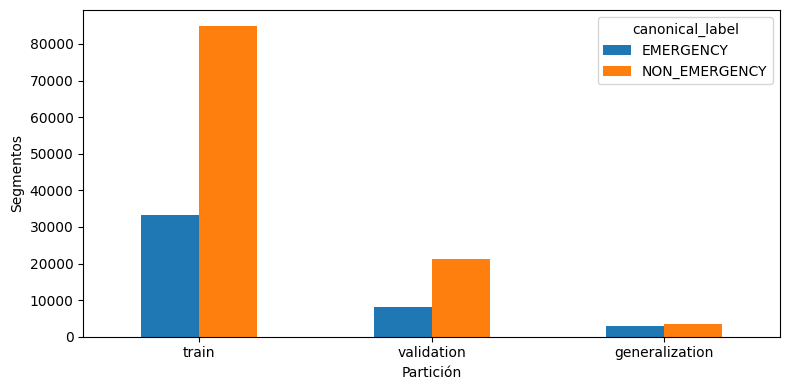

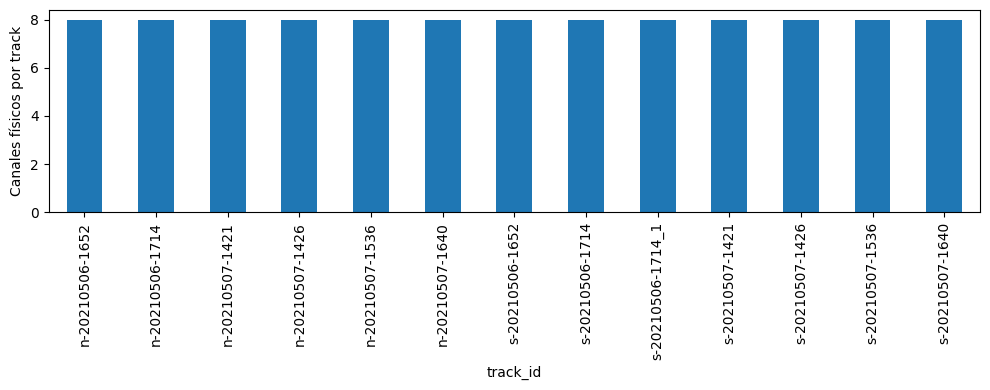

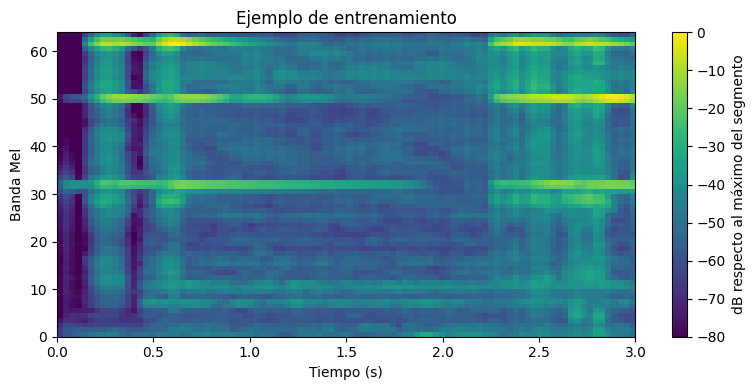

08:14:49 | stage_end | stage=reports_figures | seconds=2.9886


In [54]:
with stage_guard("reports_figures"):
    counts = (
        SEGMENTS.groupby(["split", "canonical_label"])
        .size()
        .unstack(fill_value=0)
        .reindex(["train", "validation", "generalization"])
    )

    counts.plot.bar(figsize=(8, 4))

    plt.ylabel("Segmentos")

    plt.xlabel("Partición")

    plt.xticks(rotation=0)

    save_figure("distribucion_splits")

    a3_inventory.plot.bar(x="track_id", y="channels", legend=False, figsize=(10, 4))

    plt.ylabel("Canales físicos por track")

    save_figure("inventario_a3")

    example = SEGMENTS[SEGMENTS.split.eq("train")].iloc[0]

    plt.figure(figsize=(8, 4))

    plt.imshow(
        np.load(OUT / example.representation_path, mmap_mode="r", allow_pickle=False)[
            int(example.representation_row)
        ],
        origin="lower",
        aspect="auto",
        extent=[0, CFG["window_seconds"], 0, CFG["n_mels"]],
    )

    plt.xlabel("Tiempo (s)")

    plt.ylabel("Banda Mel")

    plt.colorbar(label="dB respecto al máximo del segmento")

    plt.title("Ejemplo de entrenamiento")

    save_figure("logmel_train_example")

    report = f"""# Preparación completada
    \nArchivos inventariados: {len(RAW)}. Archivos conservados: {len(CLEAN)}. Segmentos: {len(SEGMENTS)}.
    \nProtocolo: {SR} Hz, mono por WAV, normalización {CFG["amplitude_normalization"]}, ventanas de {CFG["window_seconds"]} s y hop de {CFG["hop_seconds"]} s; consultar configuración para valores efectivos.
    \nLos originales permanecen en sus corpus. Los canales A3 permanecen identificados individualmente y agrupados por track. No se realiza localización espacial ni se presume sincronización adicional.
    \nLSSiren se prepara para uso posterior y solo ocupa generalization. No se ha entrenado ni evaluado ningún modelo.
    \nNo se ajustaron escaladores, no se seleccionaron variables por rendimiento y no se generaron nuevos aumentos. Hay etiquetas débiles heredadas de archivo/track.
    \nLa regla de AudioSet combina pertenencia a listas curadas EV_Positives/EV_Negatives y carpetas coincidentes. positive_labels se conserva para auditoría; no se afirma etiquetado temporal verificado.
    \nEsta ejecución materializa el contrato compacto v3. Los conteos y el desempeño deben verificarse al ejecutar; utilice esta misma preparación en los cinco modelos.
    \nLas ventanas solapadas no son observaciones independientes. El SHA de partición es {SPLIT_HASH}.
    \nRevise reports/independence_scope.json para la procedencia no recuperada de aumentos y otros límites.
    """

    (OUT / "reports/informe_preparacion.md").write_text(report, encoding="utf-8")

## 7. Artefactos para Kaggle

`prepared_data_v3_completo.zip` contiene metadata, particiones, características y matrices; adjúntalo como dataset a los cinco modelos. `prepared_data_v3_reportes.zip` contiene evidencia de preparación y no sirve para entrenar. Los ZIP se publican tras comprobar su integridad.


In [55]:
def export_preparation():
    """El READY certifica datos validados; COMPLETE añade exportación verificada."""
    started = time.perf_counter()
    hashes = {}
    for folder in ["metadata", "splits", "features", "config", "representations"]:
        for path in sorted((OUT / folder).rglob("*")):
            if path.is_file():
                hashes[path.relative_to(OUT).as_posix()] = sha_file(path)
    write_json(OUT / "reports/artifact_hashes.json", hashes)
    write_json(
        OUT / "PREPARATION_READY.json",
        {
            "status": "READY",
            "config_sha256": CONFIG_HASH,
            "file_split_sha256": SPLIT_HASH,
            "files": len(CLEAN),
            "segments": len(SEGMENTS),
            "schema_version": "doppler-prepared-v3",
            "features_scaled": False,
            "representation_layout": "split_arrays",
            "external_evaluated": False,
        },
    )
    report_zip = OUT.parent / (OUT.name + "_reportes.zip")

    def report_entries():
        for folder in ["metadata", "splits", "reports", "figures", "config", "logs"]:
            for path in sorted((OUT / folder).rglob("*")):
                if path.is_file():
                    yield path, "prepared_data/" + path.relative_to(OUT).as_posix()
        yield OUT / "PREPARATION_READY.json", "prepared_data/PREPARATION_READY.json"

    full_zip = None
    if CFG["make_full_zip"]:
        full_zip = OUT.parent / (OUT.name + "_completo.zip")
        entries = (
            (path, "prepared_data/" + path.relative_to(OUT).as_posix())
            for path in sorted(OUT.rglob("*"))
            if path.is_file() and path.relative_to(OUT).parts[0] != "_staging"
        )
        atomic_zip(full_zip, entries)
    COSTS.append({"phase": "exportacion_zip", "seconds": time.perf_counter() - started})
    table("reports/computational_cost.csv", COSTS)
    event("preparation_complete", segments=len(SEGMENTS), files=len(CLEAN))
    write_json(
        OUT / "reports/run_status.json",
        {"status": "COMPLETE", "external_evaluated": False},
    )
    atomic_zip(report_zip, report_entries())
    print("Paquete completo:", full_zip)
    print("Informe de preparación:", report_zip)
    return full_zip, report_zip

## Cierre de la ejecución

Comprueba el estado final y conserva los archivos de configuración, particiones, hashes y modelos.
Las tablas y figuras se generan al ejecutar esta notebook; la fuente del repositorio no incluye
resultados antiguos. Las nuevas salidas se revisarán después de su ejecución en Kaggle.


In [56]:
with stage_guard("export"):
    FULL_ZIP, REPORT_ZIP = export_preparation()

08:14:49 | stage_start | stage=export
08:20:34 | preparation_complete | segments=153993 | files=32204
Paquete completo: /kaggle/working/prepared_data_v3_completo.zip
Informe de preparación: /kaggle/working/prepared_data_v3_reportes.zip
08:20:43 | stage_end | stage=export | seconds=353.76


In [57]:
from IPython.display import FileLink

# Genera un enlace directo para descargar el archivo ZIP
FileLink(r'prepared_data_v3_completo.zip')


/kaggle/working/prepared_data_v3_completo.zip